In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [3]:
from google.colab import files
uploaded = files.upload()

Saving Sales.csv to Sales.csv


In [4]:
sales = pd.read_csv("Sales.csv")
print("Sales Dataset Shape:", sales.shape)

Sales Dataset Shape: (4000, 7)


In [5]:
df = sales.copy()
df.head()

,Date,Store,Price,Advertising,Promotion,Holiday,Sales
0,2022-04-08,6,75.06,7757.24,1,0,981.36
1,2024-04-28,3,95.28,7243.78,0,1,886.77
2,2023-12-19,3,58.77,3644.71,1,0,796.98
3,2023-04-27,5,122.13,6443.04,0,1,830.08
4,2023-04-20,1,72.17,2355.23,1,0,631.10


In [6]:
print(df.columns)
print("Missing Values:")
print(df.isnull().sum())

Index(['Date', 'Store', 'Price', 'Advertising', 'Promotion', 'Holiday',
       'Sales'],
      dtype='object')
Missing Values:
Date           0
Store          0
Price          0
Advertising    0
Promotion      0
Holiday        0
Sales          0
dtype: int64


In [7]:
df["Date"] = pd.to_datetime(df["Date"])
df["Month"] = df["Date"].dt.month
df["Year"] = df["Date"].dt.year
df = df.drop(columns=["Date"])

In [8]:
print(df["Sales"].describe())

count    4000.000000
mean      721.678090
std       176.853383
min       233.520000
25%       601.537500
50%       720.265000
75%       847.837500
max      1257.320000
Name: Sales, dtype: float64


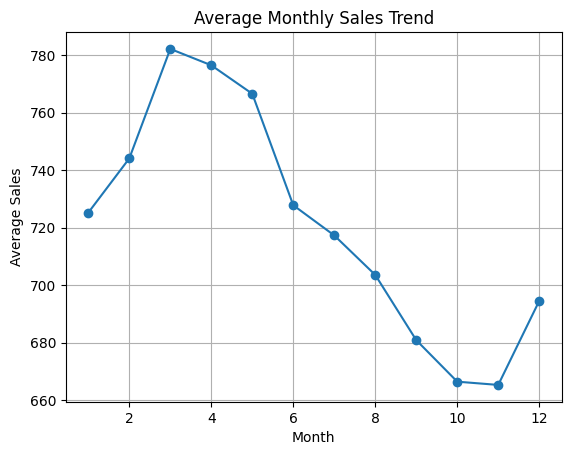

In [9]:
monthly = df.groupby("Month")["Sales"].mean()
monthly.plot(kind="line", marker="o")
plt.xlabel("Month")
plt.ylabel("Average Sales")
plt.title("Average Monthly Sales Trend")
plt.grid(True)
plt.show()

In [10]:
X = df.drop(columns=["Sales"])
y = df["Sales"]

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)
print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)


Training Data: (3200, 7)
Testing Data: (800, 7)


In [13]:
model = LinearRegression()
model.fit(X_train, y_train)
print("Model Training Completed!")

Model Training Completed!


In [14]:
y_pred = model.predict(X_test)
print(np.round(y_pred[:5], 2))

[ 785.14  281.92 1004.07  767.9   543.88]


In [15]:
print("MAE :", mean_absolute_error(y_test, y_pred))
print("MSE :", mean_squared_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2 Score:", r2_score(y_test, y_pred))

MAE : 55.67177670603851
MSE : 4886.8769606021815
RMSE: 69.9062011598555
R2 Score: 0.8496016686021244


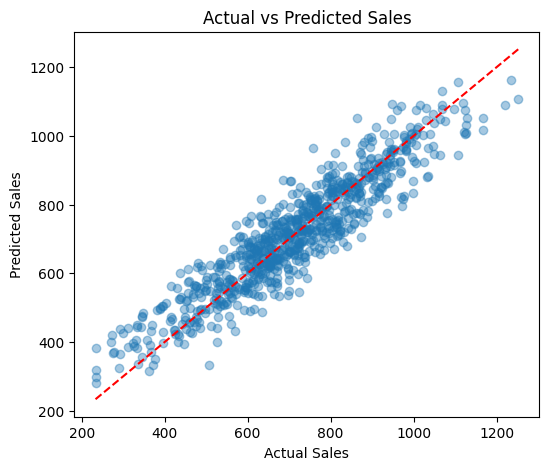

In [16]:
plt.figure(figsize=(6, 5))
plt.scatter(y_test, y_pred, alpha=0.4)
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()], "r--")
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual vs Predicted Sales")
plt.show()

In [17]:
def predict_sales(store, price, advertising, promotion, holiday, month, year):
    data = pd.DataFrame(
        [[store, price, advertising, promotion, holiday, month, year]],
        columns=X.columns
    )
    return model.predict(data)[0]
result = predict_sales(3, 99.99, 6500, 1, 0, 12, 2024)
print("Predicted Sales: %.2f units" % result)

Predicted Sales: 729.56 units
